In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mysql.connector
import warnings
warnings.filterwarnings("ignore")

In [2]:
df_cust = pd.read_csv('dataset/customers.csv')
df_cs = pd.read_csv('dataset/credit_profiles.csv')
df_trans = pd.read_csv('dataset/transactions.csv')

In [3]:
df_trans.head(4)

,tran_id,cust_id,tran_date,tran_amount,platform,product_category,payment_type
0,1,705,2023-01-01,63,Flipkart,Electronics,Phonepe
1,2,385,2023-01-01,99,Alibaba,Fashion & Apparel,Credit Card
2,3,924,2023-01-01,471,Shopify,Sports,Phonepe
3,4,797,2023-01-01,33,Shopify,Fashion & Apparel,Gpay


In [4]:
df_trans.shape

(500000, 7)

In [8]:
conn = mysql.connector.connect(
    host='localhost',
    user='root',
    password='root',
    database='e_master_card'
)

In [9]:
df_cust_sql = pd.read_sql("SELECT * FROM customers", conn)
df_cust_sql.head(5)

C:\Users\user\AppData\Local\Temp\ipykernel_3720\1494176926.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_cust_sql = pd.read_sql("SELECT * FROM customers", conn)


,cust_id,name,gender,age,location,occupation,annual_income,marital_status
0,1,Dhruv Bansal,Female,2,City,Business Owner,358211.0,Married
1,2,Kabir Thakur,Female,47,City,Consultant,65172.0,Single
2,3,Kriti Mangal,Male,21,City,Freelancer,22378.0,Married
3,4,Sara Dwivedi,Male,24,Rural,Freelancer,33563.0,Married
4,5,Aarohi Negi,Male,48,City,Consultant,39406.0,Married


In [10]:
df_cust_sql.describe()

,cust_id,age,annual_income
count,1000.000000,1000.000000,950.000000
mean,500.500000,36.405000,139410.314737
std,288.819436,15.666155,112416.802007
min,1.000000,1.000000,2.000000
25%,250.750000,26.000000,47627.500000
50%,500.500000,32.000000,112218.500000
75%,750.250000,46.000000,193137.500000
max,1000.000000,135.000000,449346.000000


In [13]:
df_cust_sql.isnull().sum()

cust_id            0
name               0
gender             0
age                0
location           0
occupation         0
annual_income     50
marital_status     0
dtype: int64

# Handle Annual income col - treat null and outliner values

In [15]:
df_cust_sql[df_cust_sql.annual_income.isnull()].head(5)

,cust_id,name,gender,age,location,occupation,annual_income,marital_status
14,15,Isha Arora,Female,25,Rural,Artist,NaN,Married
82,83,Sanjana Singhal,Male,27,City,Freelancer,NaN,Single
97,98,Sia Batra,Male,47,Suburb,Business Owner,NaN,Married
102,103,Pooja Ganguly,Male,32,City,Data Scientist,NaN,Married
155,156,Krishna Trivedi,Male,24,City,Fullstack Developer,NaN,Married


In [16]:
df_cust_sql[df_cust_sql.annual_income.isnull()].shape

(50, 8)

In [17]:
df_cust_sql.occupation.unique()

array(['Business Owner', 'Consultant', 'Freelancer',
       'Fullstack Developer', 'Accountant', 'Data Scientist', 'Artist'],
      dtype=object)

In [21]:
occ_inc_median = df_cust.groupby('occupation')['annual_income'].median()
occ_inc_median

occupation
Accountant              65265.0
Artist                  45794.0
Business Owner         261191.5
Consultant              58017.0
Data Scientist         135759.0
Freelancer              46759.0
Fullstack Developer     76774.0
Name: annual_income, dtype: float64

In [23]:
def get_median_income(row):
    if pd.isnull(row['annual_income']):
        return occ_inc_median[row['occupation']]
    else:
        return row['annual_income']

In [26]:
df_cust_sql['annual_income'] = df_cust.apply(get_median_income,axis=1)

In [27]:
df_cust_sql.isnull().sum()

cust_id           0
name              0
gender            0
age               0
location          0
occupation        0
annual_income     0
marital_status    0
dtype: int64

In [31]:
df_cust_sql.iloc[[14, 82, 97, 102, 155]]

,cust_id,name,gender,age,location,occupation,annual_income,marital_status
14,15,Isha Arora,Female,25,Rural,Artist,45794.0,Married
82,83,Sanjana Singhal,Male,27,City,Freelancer,46759.0,Single
97,98,Sia Batra,Male,47,Suburb,Business Owner,261191.5,Married
102,103,Pooja Ganguly,Male,32,City,Data Scientist,135759.0,Married
155,156,Krishna Trivedi,Male,24,City,Fullstack Developer,76774.0,Married


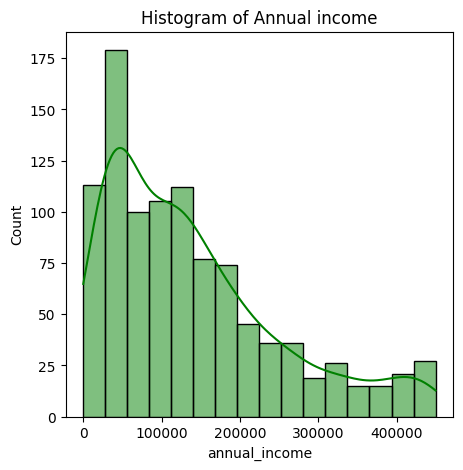

In [34]:
plt.figure(figsize=(5,5))
sns.histplot(df_cust_sql['annual_income'], kde=True, color='green', label='Data')
plt.title("Histogram of Annual income")
plt.show()

In [36]:
df_cust_sql[df_cust_sql.annual_income < 100]

,cust_id,name,gender,age,location,occupation,annual_income,marital_status
31,32,Veer Gambhir,Male,50,City,Business Owner,50.0,Married
262,263,Veer Rathod,Male,53,Suburb,Business Owner,50.0,Married
316,317,Avinash Chauhan,Male,47,City,Consultant,50.0,Married
333,334,Samaira D'Souza,Female,29,City,Data Scientist,50.0,Married
340,341,Ridhi Rastogi,Female,33,Rural,Fullstack Developer,50.0,Married
543,544,Gauri Gupta,Male,54,City,Consultant,2.0,Married
592,593,Vivaan Pande,Female,32,City,Business Owner,50.0,Married
633,634,Aradhya Pandey,Male,26,City,Data Scientist,2.0,Married
686,687,Gauri Nanda,Male,40,City,Business Owner,2.0,Married
696,697,Avani Lalwani,Male,47,City,Consultant,20.0,Married


In [38]:
for index, row in df_cust_sql.iterrows():
    if row['annual_income'] < 100:
        df_cust_sql.at[index, "annual_income"] = occ_inc_median[row['occupation']]

In [39]:
df_cust_sql[df_cust_sql.annual_income < 100]

,cust_id,name,gender,age,location,occupation,annual_income,marital_status


In [40]:
occ_inc_mean = df_cust.groupby('occupation')['annual_income'].mean()
occ_inc_mean

occupation
Accountant              64123.562500
Artist                  45309.236842
Business Owner         264832.787197
Consultant              58909.556701
Data Scientist         135545.907609
Freelancer              76327.508772
Fullstack Developer     78209.567568
Name: annual_income, dtype: float64

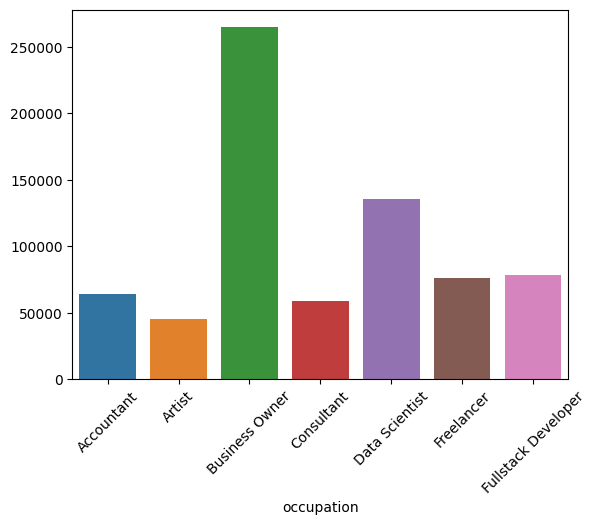

In [46]:
sns.barplot(x=occ_inc_mean.index, y=occ_inc_mean.values, palette='tab10')
plt.xticks(rotation=45)
plt.show()

In [47]:
df_cust_sql.head()

,cust_id,name,gender,age,location,occupation,annual_income,marital_status
0,1,Dhruv Bansal,Female,2,City,Business Owner,358211.0,Married
1,2,Kabir Thakur,Female,47,City,Consultant,65172.0,Single
2,3,Kriti Mangal,Male,21,City,Freelancer,22378.0,Married
3,4,Sara Dwivedi,Male,24,Rural,Freelancer,33563.0,Married
4,5,Aarohi Negi,Male,48,City,Consultant,39406.0,Married


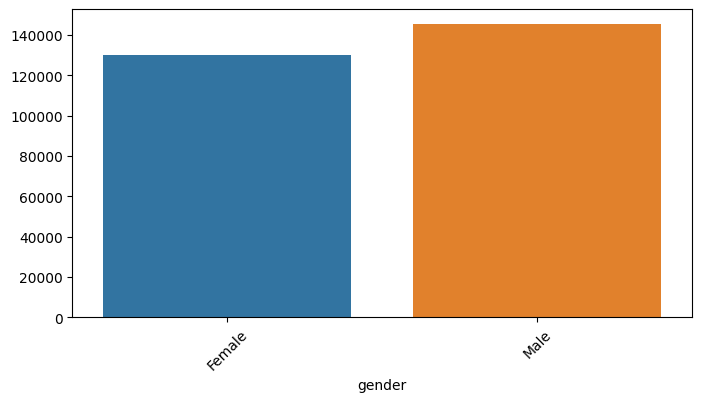

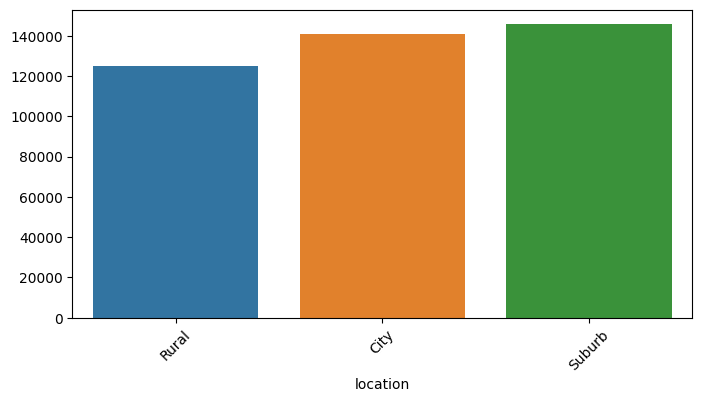

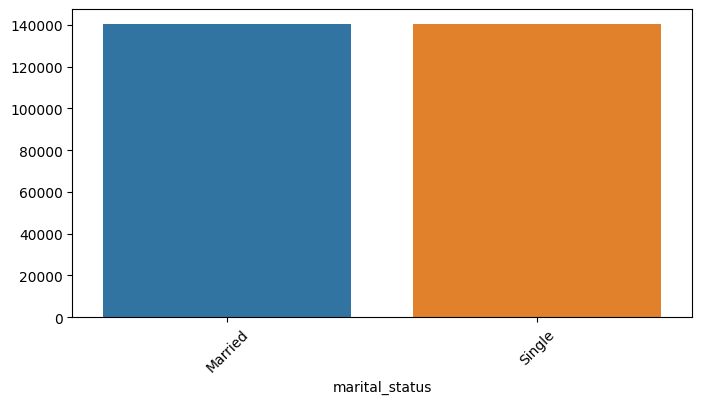

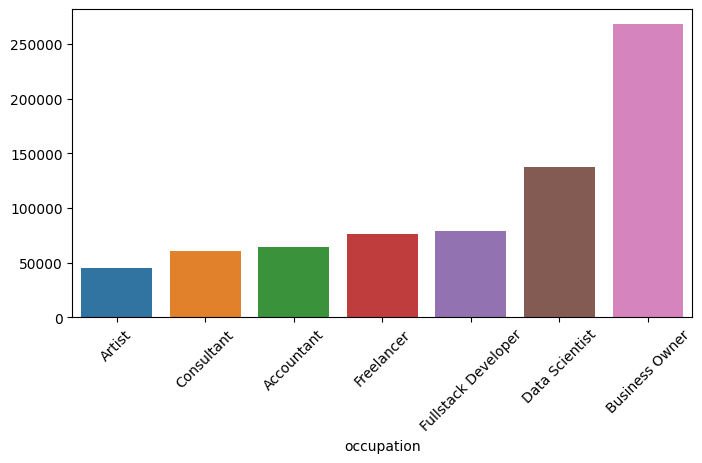

In [53]:
categorical_columns = ["gender", "location", "marital_status", "occupation"]

for col in categorical_columns:
    plt.figure(figsize=(8,4))
    avg_income_grp = df_cust_sql.groupby(col)['annual_income'].mean().sort_values()
    sns.barplot(x=avg_income_grp.index, y=avg_income_grp.values, palette='tab10')
    plt.xticks(rotation=45)
plt.show()

# Handle Age col - treat outliner values

In [55]:
df_cust_sql.age.describe()

count    1000.000000
mean       36.405000
std        15.666155
min         1.000000
25%        26.000000
50%        32.000000
75%        46.000000
max       135.000000
Name: age, dtype: float64

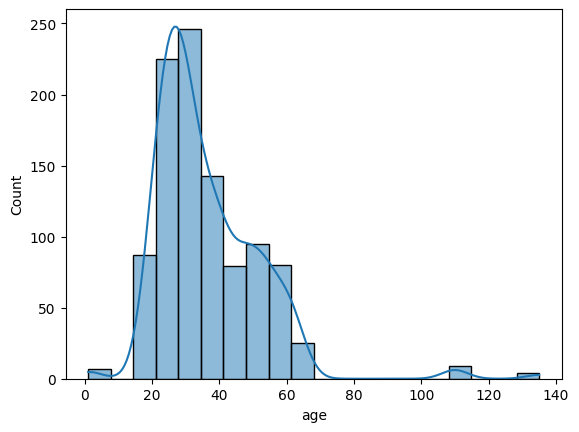

In [59]:
sns.histplot(df_cust_sql.age, kde=True, bins=20)
plt.show()

In [61]:
df_cust_sql[(df_cust_sql.age < 15) | (df_cust_sql.age > 80)].shape

(20, 8)

In [66]:
age_per_occ_median = df_cust_sql.groupby("occupation")["age"].median()
age_per_occ_median

occupation
Accountant             31.5
Artist                 26.0
Business Owner         51.0
Consultant             46.0
Data Scientist         32.0
Freelancer             24.0
Fullstack Developer    27.5
Name: age, dtype: float64

In [70]:
age_outliers = df_cust_sql[(df_cust_sql.age < 15) | (df_cust_sql.age > 80)]
age_outliers.head()

,cust_id,name,gender,age,location,occupation,annual_income,marital_status
0,1,Dhruv Bansal,Female,2,City,Business Owner,358211.0,Married
41,42,Manya Thakur,Male,110,City,Artist,7621.0,Married
165,166,Swara Mehtani,Female,1,City,Freelancer,39721.0,Single
174,175,Sneha Jaiswal,Male,110,City,Freelancer,23723.0,Married
222,223,Aaryan Bajaj,Male,110,Suburb,Freelancer,210987.0,Married


In [71]:
for index, row in age_outliers.iterrows():
    df_cust_sql.at[index, 'age'] = age_per_occ_median[row['occupation']]

In [72]:
age_outliers = df_cust_sql[(df_cust_sql.age < 15) | (df_cust_sql.age > 80)]
age_outliers.head()

,cust_id,name,gender,age,location,occupation,annual_income,marital_status


In [74]:
df_cust_sql.age.describe()

count    1000.000000
mean       35.541500
std        12.276634
min        18.000000
25%        26.000000
50%        32.000000
75%        44.250000
max        64.000000
Name: age, dtype: float64

In [90]:
bins = [17, 25, 48, 65]
labels = ['18-25', '26-48', '49-65']
df_cust_sql['age_grp'] = pd.cut(df_cust_sql['age'], bins=bins, labels=labels)
df_cust_sql

,cust_id,name,gender,age,location,occupation,annual_income,marital_status,age_grp
0,1,Dhruv Bansal,Female,51.0,City,Business Owner,358211.0,Married,49-65
1,2,Kabir Thakur,Female,47.0,City,Consultant,65172.0,Single,26-48
2,3,Kriti Mangal,Male,21.0,City,Freelancer,22378.0,Married,18-25
3,4,Sara Dwivedi,Male,24.0,Rural,Freelancer,33563.0,Married,18-25
4,5,Aarohi Negi,Male,48.0,City,Consultant,39406.0,Married,26-48
...,...,...,...,...,...,...,...,...,...
995,996,Advait Rana,Female,26.0,City,Freelancer,46759.0,Married,26-48
996,997,Sia Chatterjee,Male,55.0,City,Business Owner,290061.0,Single,49-65
997,998,Amara Tiwari,Male,29.0,City,Fullstack Developer,139141.0,Married,26-48
998,999,Aanya Malhotra,Female,47.0,City,Business Owner,261191.5,Married,26-48


In [92]:
age_grp_count = df_cust_sql.age_grp.value_counts()
age_grp_count

age_grp
26-48    567
18-25    246
49-65    187
Name: count, dtype: int64

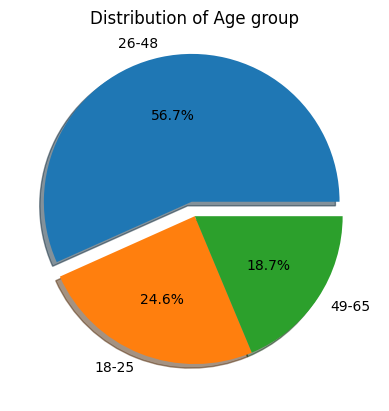

In [99]:
plt.pie(
    age_grp_count,
    labels=age_grp_count.index,
    autopct='%1.1f%%',
    shadow=True,
    explode=(0.1, 0, 0)
)
plt.title("Distribution of Age group")
plt.show()

In [100]:
df_cust_sql.location.value_counts()

location
City      683
Suburb    232
Rural      85
Name: count, dtype: int64

In [101]:
df_cust_sql.gender.value_counts()

gender
Male      674
Female    326
Name: count, dtype: int64

In [105]:
cus_loc_gen = df_cust_sql.groupby(['location', 'gender']).size().unstack()
cus_loc_gen

gender,Female,Male
location,,
City,226,457
Rural,26,59
Suburb,74,158


<Axes: xlabel='location'>

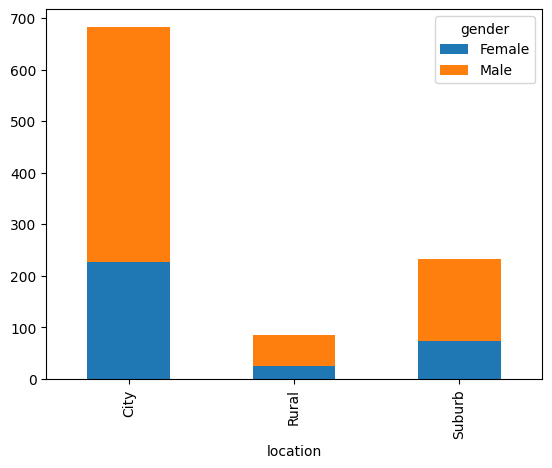

In [107]:
cus_loc_gen.plot(kind='bar', stacked=True)

# Explore Credit Score Table

In [108]:
df_cs.head()

,cust_id,credit_score,credit_utilisation,outstanding_debt,credit_inquiries_last_6_months,credit_limit
0,1,749,0.585171,19571.0,0.0,40000.0
1,2,587,0.107928,161644.0,2.0,1250.0
2,3,544,0.854807,513.0,4.0,1000.0
3,4,504,0.336938,224.0,2.0,1000.0
4,5,708,0.586151,18090.0,2.0,40000.0


In [109]:
df_cs.shape

(1004, 6)

In [110]:
df_cust_sql.shape

(1000, 9)

In [112]:
df_cs['cust_id'].nunique()

1000

In [115]:
df_cs[df_cs['cust_id'].duplicated(keep=False)]

,cust_id,credit_score,credit_utilisation,outstanding_debt,credit_inquiries_last_6_months,credit_limit
516,517,308,NaN,NaN,NaN,NaN
517,517,308,0.113860,33.0,3.0,500.0
569,569,344,NaN,NaN,NaN,NaN
570,569,344,0.112599,37.0,0.0,500.0
607,606,734,NaN,NaN,NaN,NaN
608,606,734,0.193418,4392.0,1.0,40000.0
664,662,442,NaN,NaN,NaN,NaN
665,662,442,0.856039,266.0,2.0,500.0


In [118]:
df_cs = df_cs.drop_duplicates(subset="cust_id", keep='last')
df_cs.shape

(1000, 6)

In [119]:
df_cs.isnull().sum()

cust_id                            0
credit_score                       0
credit_utilisation                 0
outstanding_debt                   0
credit_inquiries_last_6_months     0
credit_limit                      65
dtype: int64

In [120]:
df_cs[df_cs.credit_limit.isnull()]

,cust_id,credit_score,credit_utilisation,outstanding_debt,credit_inquiries_last_6_months,credit_limit
10,11,679,0.557450,9187.0,2.0,NaN
35,36,790,0.112535,4261.0,1.0,NaN
37,38,514,0.296971,238.0,2.0,NaN
45,46,761,0.596041,24234.0,2.0,NaN
64,65,734,0.473715,13631.0,0.0,NaN
...,...,...,...,...,...,...
912,909,479,0.487555,320.0,3.0,NaN
931,928,311,0.832244,316.0,2.0,NaN
948,945,526,0.272734,227.0,1.0,NaN
954,951,513,0.175914,131.0,3.0,NaN


In [121]:
df_cs.credit_limit.value_counts()

credit_limit
500.0      229
60000.0    186
40000.0    137
1500.0     100
1000.0      90
750.0       76
1250.0      75
20000.0     42
Name: count, dtype: int64

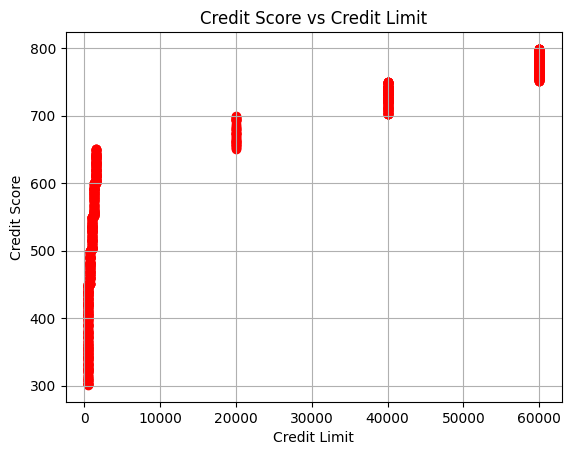

In [130]:
plt.scatter(df_cs.credit_limit, df_cs.credit_score, c='red')

plt.title("Credit Score vs Credit Limit")
plt.xlabel('Credit Limit')
plt.ylabel('Credit Score')

plt.grid(True)

plt.show()

In [132]:
bin_ranges = [300, 450, 500, 550, 600, 650, 700, 750, 800]
bin_labels = [f'{start}-{end-1}' for start, end in zip(bin_ranges, bin_ranges[1:])]
bin_labels

['300-449',
 '450-499',
 '500-549',
 '550-599',
 '600-649',
 '650-699',
 '700-749',
 '750-799']

In [135]:
df_cs['credit_score_range'] = pd.cut(df_cs['credit_score'], bins=bin_ranges, labels=bin_labels)

In [136]:
df_cs.sample(6)

,cust_id,credit_score,credit_utilisation,outstanding_debt,credit_inquiries_last_6_months,credit_limit,credit_score_range
20,21,381,0.714710,307.0,0.0,500.0,300-449
486,487,464,0.289108,155.0,0.0,750.0,450-499
491,492,763,0.319136,12853.0,1.0,60000.0,750-799
2,3,544,0.854807,513.0,4.0,1000.0,500-549
198,199,301,0.108910,37.0,2.0,500.0,300-449
50,51,535,0.483264,253.0,1.0,1000.0,500-549


In [137]:
df_cs[df_cs.credit_score_range == '700-749']

,cust_id,credit_score,credit_utilisation,outstanding_debt,credit_inquiries_last_6_months,credit_limit,credit_score_range
0,1,749,0.585171,19571.0,0.0,40000.0,700-749
4,5,708,0.586151,18090.0,2.0,40000.0,700-749
6,7,747,0.523965,15544.0,4.0,40000.0,700-749
16,17,702,0.894423,18444.0,0.0,40000.0,700-749
27,28,729,0.149748,3453.0,2.0,40000.0,700-749
...,...,...,...,...,...,...,...
969,966,720,0.203742,6159.0,4.0,40000.0,700-749
970,967,739,0.845474,23929.0,4.0,40000.0,700-749
991,988,739,0.435891,9283.0,4.0,40000.0,700-749
994,991,709,0.718484,15473.0,4.0,40000.0,700-749


In [140]:
df_cs.groupby("credit_score_range")["credit_limit"].agg(lambda x: x.mode().iloc[0])

credit_score_range
300-449      500.0
450-499      750.0
500-549     1000.0
550-599     1250.0
600-649     1500.0
650-699    20000.0
700-749    40000.0
750-799    60000.0
Name: credit_limit, dtype: float64

In [142]:
df_cs_mode = df_cs.groupby("credit_score_range")["credit_limit"].agg(lambda x: x.mode().iloc[0]).reset_index()
df_cs_mode

,credit_score_range,credit_limit
0,300-449,500.0
1,450-499,750.0
2,500-549,1000.0
3,550-599,1250.0
4,600-649,1500.0
5,650-699,20000.0
6,700-749,40000.0
7,750-799,60000.0


In [152]:
def give_credit_limit(row):
    if pd.notna(row['credit_limit']):
        return row['credit_limit']

    for index, r in df_cs_mode.iterrows():
        if r['credit_score_range'] == row['credit_score_range']:
            return r['credit_limit']

    return row['credit_limit']


df_cs['credit_limit'] = df_cs.apply(give_credit_limit, axis=1)

In [155]:
df_cs.drop(index=680, inplace=True)

In [156]:
df_cs.describe()

,cust_id,credit_score,credit_utilisation,outstanding_debt,credit_inquiries_last_6_months,credit_limit
count,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000
mean,500.323323,589.471471,0.498663,9692.948949,1.955956,19752.752753
std,288.910029,152.085696,0.233079,25266.811373,1.414944,24722.506641
min,1.000000,301.000000,0.103761,33.000000,0.000000,500.000000
25%,250.500000,460.000000,0.293785,221.000000,1.000000,750.000000
50%,500.000000,602.000000,0.487290,551.000000,2.000000,1500.000000
75%,750.500000,738.000000,0.697670,11839.000000,3.000000,40000.000000
max,1000.000000,799.000000,0.899648,209901.000000,4.000000,60000.000000


<Axes: xlabel='outstanding_debt', ylabel='Count'>

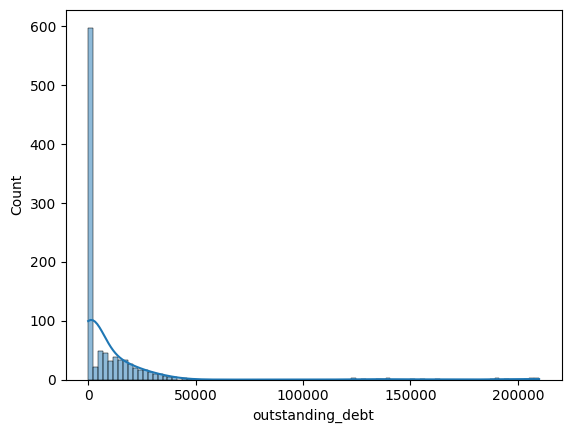

In [158]:
sns.histplot(df_cs['outstanding_debt'], kde=True)

In [160]:
df_cs[df_cs['outstanding_debt'] > df_cs['credit_limit']]

,cust_id,credit_score,credit_utilisation,outstanding_debt,credit_inquiries_last_6_months,credit_limit,credit_score_range
1,2,587,0.107928,161644.0,2.0,1250.0,550-599
19,20,647,0.439132,205014.0,3.0,1500.0,600-649
25,26,758,0.250811,190838.0,2.0,60000.0,750-799
38,39,734,0.573023,122758.0,3.0,40000.0,700-749
93,94,737,0.739948,137058.0,2.0,40000.0,700-749
204,205,303,0.364360,187849.0,0.0,500.0,300-449
271,272,703,0.446886,154568.0,1.0,40000.0,700-749
301,302,722,0.608076,122402.0,4.0,40000.0,700-749
330,331,799,0.363420,208898.0,4.0,60000.0,750-799
350,351,320,0.285081,150860.0,0.0,500.0,300-449


In [162]:
df_cs.loc[df_cs.outstanding_debt > df_cs.credit_limit, 'outstanding_debt'] = df_cs.credit_limit

In [163]:
df_cs[df_cs['outstanding_debt'] > df_cs['credit_limit']]

,cust_id,credit_score,credit_utilisation,outstanding_debt,credit_inquiries_last_6_months,credit_limit,credit_score_range


In [164]:
df_merged = df_cust_sql.merge(df_cs, on='cust_id', how='inner')
df_merged

,cust_id,name,gender,age,location,occupation,annual_income,marital_status,age_grp,credit_score,credit_utilisation,outstanding_debt,credit_inquiries_last_6_months,credit_limit,credit_score_range
0,1,Dhruv Bansal,Female,51.0,City,Business Owner,358211.0,Married,49-65,749,0.585171,19571.0,0.0,40000.0,700-749
1,2,Kabir Thakur,Female,47.0,City,Consultant,65172.0,Single,26-48,587,0.107928,1250.0,2.0,1250.0,550-599
2,3,Kriti Mangal,Male,21.0,City,Freelancer,22378.0,Married,18-25,544,0.854807,513.0,4.0,1000.0,500-549
3,4,Sara Dwivedi,Male,24.0,Rural,Freelancer,33563.0,Married,18-25,504,0.336938,224.0,2.0,1000.0,500-549
4,5,Aarohi Negi,Male,48.0,City,Consultant,39406.0,Married,26-48,708,0.586151,18090.0,2.0,40000.0,700-749
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
994,996,Advait Rana,Female,26.0,City,Freelancer,46759.0,Married,26-48,564,0.702963,688.0,2.0,1250.0,550-599
995,997,Sia Chatterjee,Male,55.0,City,Business Owner,290061.0,Single,49-65,774,0.465462,17139.0,0.0,60000.0,750-799
996,998,Amara Tiwari,Male,29.0,City,Fullstack Developer,139141.0,Married,26-48,529,0.585856,386.0,3.0,1000.0,500-549
997,999,Aanya Malhotra,Female,47.0,City,Business Owner,261191.5,Married,26-48,725,0.249670,6973.0,2.0,40000.0,700-749


In [165]:
num_col = ['credit_score', 'credit_utilisation', 'outstanding_debt', 'credit_inquiries_last_6_months', 'credit_limit']
correlation_matrix = df_merged[num_col].corr()
correlation_matrix

,credit_score,credit_utilisation,outstanding_debt,credit_inquiries_last_6_months,credit_limit
credit_score,1.000000,-0.068281,0.680852,-0.002516,0.848261
credit_utilisation,-0.068281,1.000000,0.193771,-0.013134,-0.079631
outstanding_debt,0.680852,0.193771,1.000000,0.019389,0.810502
credit_inquiries_last_6_months,-0.002516,-0.013134,0.019389,1.000000,0.014197
credit_limit,0.848261,-0.079631,0.810502,0.014197,1.000000


<Axes: >

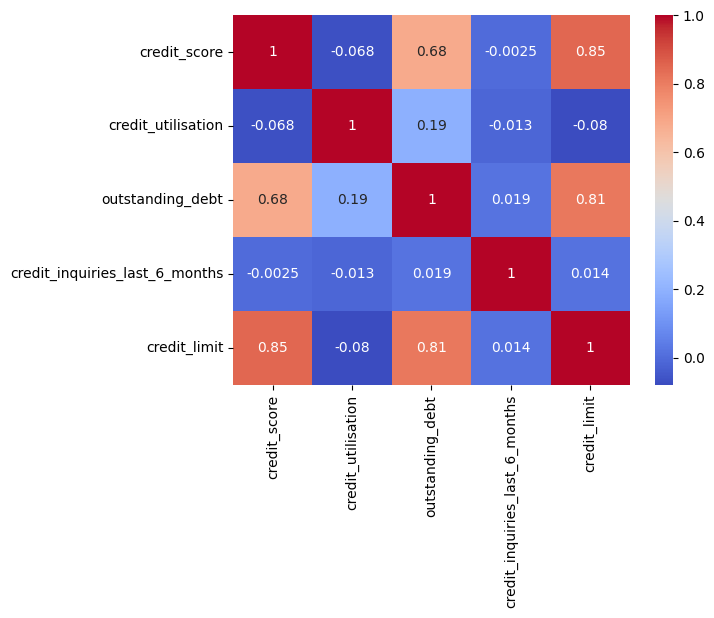

In [168]:
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')

# Transaction table Analysis

In [169]:
df_trans.head()

,tran_id,cust_id,tran_date,tran_amount,platform,product_category,payment_type
0,1,705,2023-01-01,63,Flipkart,Electronics,Phonepe
1,2,385,2023-01-01,99,Alibaba,Fashion & Apparel,Credit Card
2,3,924,2023-01-01,471,Shopify,Sports,Phonepe
3,4,797,2023-01-01,33,Shopify,Fashion & Apparel,Gpay
4,5,482,2023-01-01,68,Amazon,Fashion & Apparel,Net Banking


In [171]:
df_trans.isnull().sum()

tran_id                0
cust_id                0
tran_date              0
tran_amount            0
platform            4941
product_category       0
payment_type           0
dtype: int64

In [172]:
df_trans.platform.value_counts()

platform
Amazon      151443
Flipkart    122660
Alibaba      73584
Meesho       73271
Shopify      39416
Cred         24741
Ebay          9944
Name: count, dtype: int64

In [177]:
df_trans.product_category.value_counts()

product_category
Electronics               134535
Fashion & Apparel         116892
Kitchen Appliances         57353
Beauty & Personal Care     56065
Sports                     49704
Home Decor                 38355
Garden & Outdoor           23644
Books                      13635
Toys & Games                9817
Name: count, dtype: int64

In [179]:
df_trans.groupby('product_category')['platform'].value_counts()

product_category        platform
Beauty & Personal Care  Amazon      16581
                        Flipkart    14013
                        Alibaba      8475
                        Meesho       8013
                        Shopify      4475
                                    ...  
Toys & Games            Meesho       1521
                        Alibaba      1432
                        Shopify       757
                        Cred          460
                        Ebay          194
Name: count, Length: 63, dtype: int64

<Axes: xlabel='count', ylabel='product_category'>

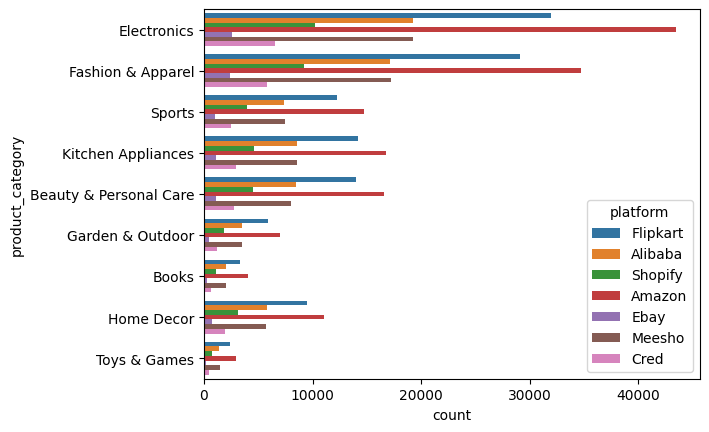

In [180]:
sns.countplot(y='product_category', hue='platform', data=df_trans)

In [181]:
df_trans.platform.fillna(df_trans.platform.mode()[0], inplace=True)

In [182]:
df_trans.isnull().sum()

tran_id             0
cust_id             0
tran_date           0
tran_amount         0
platform            0
product_category    0
payment_type        0
dtype: int64

In [183]:
df_trans.describe()

,tran_id,cust_id,tran_amount
count,500000.000000,500000.000000,500000.00000
mean,250000.500000,501.400428,3225.20733
std,144337.711635,288.641924,13098.74276
min,1.000000,1.000000,0.00000
25%,125000.750000,252.000000,64.00000
50%,250000.500000,502.000000,141.00000
75%,375000.250000,752.000000,397.00000
max,500000.000000,1000.000000,69999.00000


In [185]:
df_trans_zero = df_trans[df_trans.tran_amount == 0]
df_trans_zero.shape

(4734, 7)

In [186]:
df_trans_zero[["platform", "product_category", "payment_type"]].value_counts()

platform  product_category  payment_type
Amazon    Electronics       Credit Card     4734
Name: count, dtype: int64

In [190]:
df_tran_amount_zero = df_trans[(df_trans.platform=='Amazon')&(df_trans.product_category=='Electronics')&(df_trans.payment_type=='Credit Card')]
df_tran_amount_zero.sample(5)

,tran_id,cust_id,tran_date,tran_amount,platform,product_category,payment_type
326848,326849,429,2023-06-12,0,Amazon,Electronics,Credit Card
201274,201275,583,2023-04-10,667,Amazon,Electronics,Credit Card
208887,208888,574,2023-04-14,312,Amazon,Electronics,Credit Card
185828,185829,72,2023-04-03,334,Amazon,Electronics,Credit Card
341502,341503,920,2023-06-19,979,Amazon,Electronics,Credit Card


In [195]:
df_tran_median = df_tran_amount_zero[df_tran_amount_zero.tran_amount > 0].tran_amount.median()
df_tran_median

np.float64(554.0)

In [196]:
df_trans['tran_amount'].replace(0, df_tran_median, inplace=True)

In [197]:
df_trans[df_trans.tran_amount == 0]

,tran_id,cust_id,tran_date,tran_amount,platform,product_category,payment_type


In [200]:
Q1, Q3 = df_trans['tran_amount'].quantile([0.25, 0.75])
IQR = Q3 - Q1
lower = Q1 - 3*IQR
higher = Q3 + 3*IQR

lower, higher

(-975.0, 1454.0)

In [202]:
df_trans[df_trans.tran_amount >= higher]

,tran_id,cust_id,tran_date,tran_amount,platform,product_category,payment_type
26,27,380,2023-01-01,61963,Shopify,Beauty & Personal Care,Credit Card
49,50,287,2023-01-01,57869,Amazon,Toys & Games,Gpay
94,95,770,2023-01-01,52881,Ebay,Kitchen Appliances,Credit Card
104,105,549,2023-01-01,58574,Flipkart,Fashion & Apparel,Gpay
113,114,790,2023-01-01,51669,Shopify,Kitchen Appliances,Credit Card
...,...,...,...,...,...,...,...
499742,499743,868,2023-09-05,55131,Meesho,Fashion & Apparel,Gpay
499888,499889,614,2023-09-05,59679,Meesho,Fashion & Apparel,Net Banking
499900,499901,811,2023-09-05,60184,Flipkart,Sports,Debit Card
499966,499967,662,2023-09-05,54678,Meesho,Sports,Gpay


In [204]:
df_trans[df_trans.cust_id == 1].tran_amount.max()

np.int64(69285)

In [205]:
df_trans = df_trans.merge(
    df_cs[['cust_id', 'credit_limit']],
    on='cust_id',
    how='left'
)

In [206]:
df_trans.sample(5)

,tran_id,cust_id,tran_date,tran_amount,platform,product_category,payment_type,credit_limit
275469,275470,829,2023-05-17,43,Shopify,Electronics,Credit Card,500.0
434767,434768,145,2023-08-04,11,Amazon,Garden & Outdoor,Phonepe,40000.0
220968,220969,370,2023-04-20,554,Amazon,Electronics,Credit Card,40000.0
90845,90846,104,2023-02-14,31,Amazon,Books,Phonepe,60000.0
408265,408266,402,2023-07-22,70,Flipkart,Fashion & Apparel,Phonepe,60000.0


In [207]:
df_trans[df_trans['tran_amount'] > df_trans['credit_limit']]

,tran_id,cust_id,tran_date,tran_amount,platform,product_category,payment_type,credit_limit
9,10,228,2023-01-01,836,Ebay,Electronics,Gpay,500.0
26,27,380,2023-01-01,61963,Shopify,Beauty & Personal Care,Credit Card,60000.0
48,49,532,2023-01-01,974,Flipkart,Electronics,Debit Card,500.0
49,50,287,2023-01-01,57869,Amazon,Toys & Games,Gpay,500.0
53,54,879,2023-01-01,529,Alibaba,Sports,Phonepe,500.0
...,...,...,...,...,...,...,...,...
499908,499909,433,2023-09-05,794,Amazon,Electronics,Phonepe,500.0
499913,499914,604,2023-09-05,614,Meesho,Electronics,Gpay,500.0
499937,499938,579,2023-09-05,525,Alibaba,Sports,Phonepe,500.0
499966,499967,662,2023-09-05,54678,Meesho,Sports,Gpay,500.0


In [208]:
df_trans.loc[
    df_trans['tran_amount'] > df_trans['credit_limit'],
    'tran_amount'
] = df_trans['credit_limit']

In [209]:
df_trans[df_trans['tran_amount'] > df_trans['credit_limit']]

,tran_id,cust_id,tran_date,tran_amount,platform,product_category,payment_type,credit_limit


In [213]:
df_trans.iloc[[26, 9]]

,tran_id,cust_id,tran_date,tran_amount,platform,product_category,payment_type,credit_limit
26,27,380,2023-01-01,60000,Shopify,Beauty & Personal Care,Credit Card,60000.0
9,10,228,2023-01-01,500,Ebay,Electronics,Gpay,500.0


<Axes: xlabel='tran_amount', ylabel='Density'>

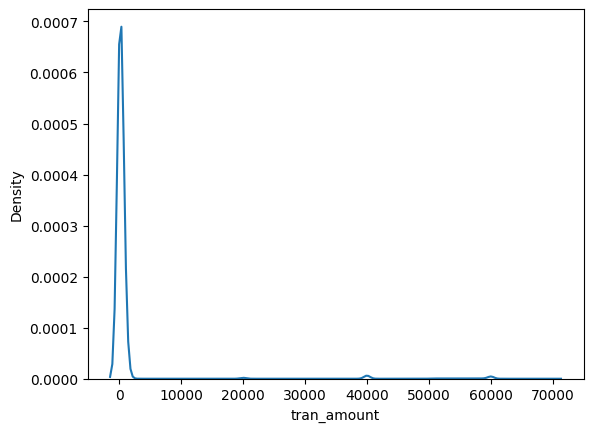

In [215]:
sns.kdeplot(df_trans.tran_amount)

<Axes: xlabel='payment_type', ylabel='percent'>

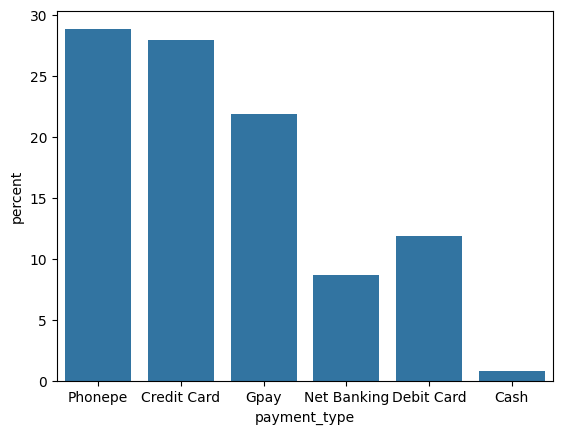

In [216]:
sns.countplot(x=df_trans.payment_type, stat='percent')

In [220]:
df_cust_sql.head()

,cust_id,name,gender,age,location,occupation,annual_income,marital_status,age_grp
0,1,Dhruv Bansal,Female,51.0,City,Business Owner,358211.0,Married,49-65
1,2,Kabir Thakur,Female,47.0,City,Consultant,65172.0,Single,26-48
2,3,Kriti Mangal,Male,21.0,City,Freelancer,22378.0,Married,18-25
3,4,Sara Dwivedi,Male,24.0,Rural,Freelancer,33563.0,Married,18-25
4,5,Aarohi Negi,Male,48.0,City,Consultant,39406.0,Married,26-48


In [221]:
df_trans_age = df_trans.merge(
    df_cust_sql[['cust_id', 'age_grp']],
    on='cust_id',
    how='left'
)
df_trans_age.sample(5)

,tran_id,cust_id,tran_date,tran_amount,platform,product_category,payment_type,credit_limit,age_grp
499017,499018,377,2023-09-05,468,Alibaba,Electronics,Phonepe,60000.0,26-48
71008,71009,763,2023-02-05,38,Amazon,Fashion & Apparel,Cash,1000.0,26-48
68235,68236,505,2023-02-03,385,Alibaba,Electronics,Gpay,60000.0,26-48
253450,253451,337,2023-05-06,149,Flipkart,Beauty & Personal Care,Credit Card,500.0,26-48
253076,253077,965,2023-05-06,57,Ebay,Fashion & Apparel,Credit Card,60000.0,49-65


<Axes: xlabel='age_grp', ylabel='percent'>

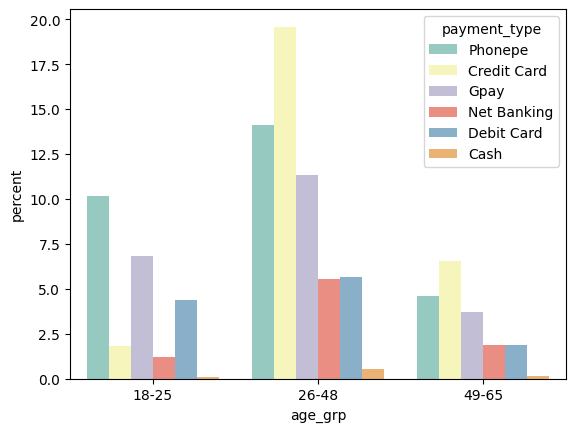

In [227]:
sns.countplot(x='age_grp', hue='payment_type', stat='percent', data=df_trans_age, palette='Set3')

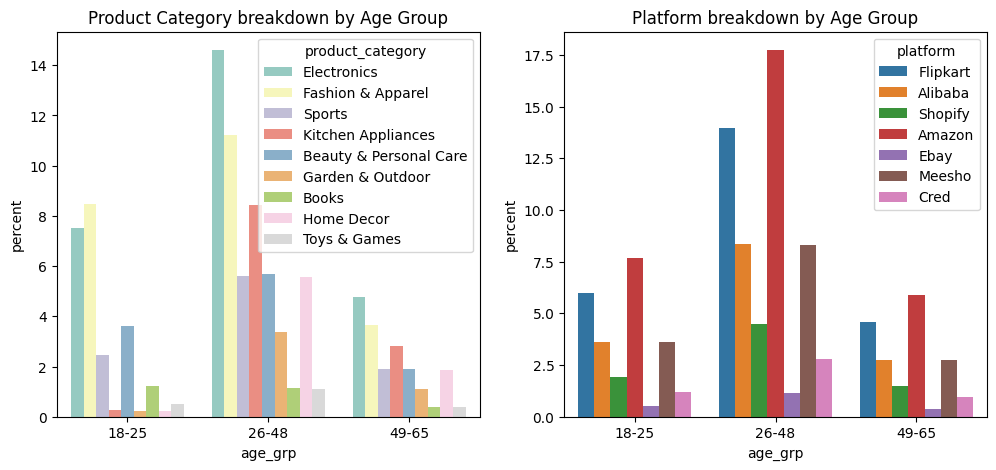

In [232]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
sns.countplot(x='age_grp', hue='product_category', stat='percent', data=df_trans_age, palette='Set3', ax=ax1)
sns.countplot(x='age_grp', hue='platform', stat='percent', data=df_trans_age, palette='tab10', ax=ax2)

ax1.set_title('Product Category breakdown by Age Group')
ax2.set_title('Platform breakdown by Age Group')

plt.show()